In [1]:
# EDA=Exploratory data analysis 

In [4]:
pip install pandas 

Note: you may need to restart the kernel to use updated packages.


In [5]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [6]:
pip install numpy

Note: you may need to restart the kernel to use updated packages.


In [7]:
pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [8]:
import pandas as pd 
import numpy as np
import seaborn as sns 
import matplotlib.pyplot as plt

In [9]:
df=pd.read_csv("Automobile_data-selected-columns.csv")

In [11]:
df.head()

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6
1,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6
2,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4


In [12]:
df.tail()

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base
200,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1
201,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1
202,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1
203,-1,95,volvo,diesel,turbo,four,sedan,rwd,front,109.1
204,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1


In [13]:
df.shape

(205, 10)

In [14]:
df.columns

Index(['symboling', 'normalized-losses', 'make', 'fuel-type', 'aspiration',
       'num-of-doors', 'body-style', 'drive-wheels', 'engine-location',
       'wheel-base'],
      dtype='str')

In [16]:
df.nunique()

symboling             6
normalized-losses    52
make                 22
fuel-type             2
aspiration            2
num-of-doors          3
body-style            5
drive-wheels          3
engine-location       2
wheel-base           53
dtype: int64

In [17]:
df['body-style'].unique()

<StringArray>
['convertible', 'hatchback', 'sedan', 'wagon', 'hardtop']
Length: 5, dtype: str

In [18]:
df.isnull().sum()

symboling            0
normalized-losses    0
make                 0
fuel-type            0
aspiration           0
num-of-doors         0
body-style           0
drive-wheels         0
engine-location      0
wheel-base           0
dtype: int64

In [19]:
df["normalized-losses"].unique()

<StringArray>
[  '?', '164', '158', '192', '188', '121',  '98',  '81', '118', '148', '110',
 '145', '137', '101',  '78', '106',  '85', '107', '104', '113', '150', '129',
 '115',  '93', '142', '161', '153', '125', '128', '122', '103', '168', '108',
 '194', '231', '119', '154',  '74', '186',  '83', '102',  '89',  '87',  '77',
  '91', '134',  '65', '197',  '90',  '94', '256',  '95']
Length: 52, dtype: str

In [20]:
df.dtypes

symboling              int64
normalized-losses        str
make                     str
fuel-type                str
aspiration               str
num-of-doors             str
body-style               str
drive-wheels             str
engine-location          str
wheel-base           float64
dtype: object

In [21]:
# how many ?(question m,ark are present in normalised-lossess)

In [ ]:
count=0
for i in df["normalized-losses"]:
    if i=='?':
        count=count+1
        lst.append(i)

In [39]:
count

41

In [35]:
print(lst,end='')

['?', '?', '?', '?', '?', '?', '?', '?', '?', '?', '?', '?', '?', '?', '?', '?', '?', '?', '?', '?', '?', '?', '?', '?', '?', '?', '?', '?', '?', '?', '?', '?', '?', '?', '?', '?', '?', '?', '?', '?', '?']

In [36]:
len(lst)

41

In [37]:
# Replace question mark with null values 

In [38]:
df['normalized-losses']=df['normalized-losses'].replace('?',np.nan)

In [40]:
df.isnull().sum()

symboling             0
normalized-losses    41
make                  0
fuel-type             0
aspiration            0
num-of-doors          0
body-style            0
drive-wheels          0
engine-location       0
wheel-base            0
dtype: int64

In [41]:
df['normalized-losses'].dtype

<StringDtype(storage='python', na_value=nan)>

In [42]:
# convert to float 

In [43]:
df['normalized-losses']=df['normalized-losses'].astype('float64')

In [44]:
df['normalized-losses'].dtype

dtype('float64')

In [45]:
# replace null values with mean 

In [47]:
df['normalized-losses'].mean()

np.float64(122.0)

In [46]:
df['normalized-losses']=df['normalized-losses'].fillna(df['normalized-losses'].mean())

In [48]:
df['normalized-losses'].head()

0    122.0
1    122.0
2    122.0
3    164.0
4    164.0
Name: normalized-losses, dtype: float64

In [49]:
# Outliers 

<Axes: xlabel='wheel-base'>

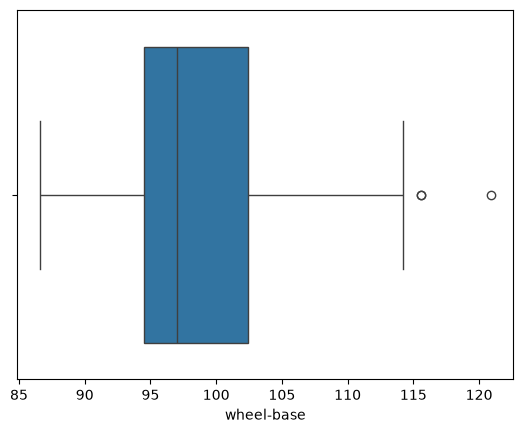

In [51]:
sns.boxplot(x='wheel-base',data=df)

In [52]:
q1=np.percentile(df['wheel-base'],25)

In [53]:
q1

np.float64(94.5)

In [54]:
q3=np.percentile(df['wheel-base'],75)

In [55]:
q3

np.float64(102.4)

In [56]:
iqr=q3-q1 
iqr

np.float64(7.900000000000006)

In [58]:
uw=q3+1.5*iqr
uw

np.float64(114.25000000000001)

In [59]:
lw=q1-1.5*iqr 
lw

np.float64(82.64999999999999)

In [ ]:
df[df['wheel-base']>uw]

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base
70,-1,93.0,mercedes-benz,diesel,turbo,four,sedan,rwd,front,115.6
71,-1,122.0,mercedes-benz,gas,std,four,sedan,rwd,front,115.6
73,0,122.0,mercedes-benz,gas,std,four,sedan,rwd,front,120.9


In [68]:
# df.drop([70,71,73],inplace=True)

In [66]:
df[df['wheel-base']>uw]


,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base


<Axes: xlabel='wheel-base'>

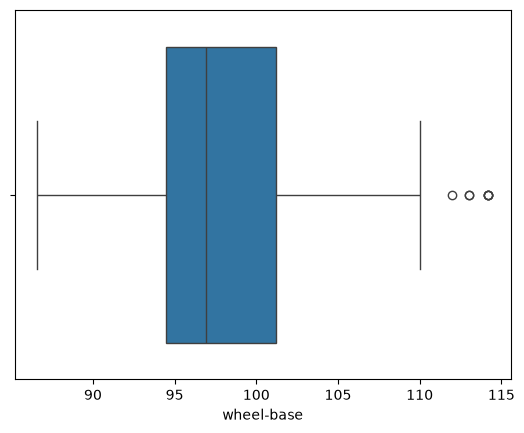

In [67]:
sns.boxplot(x="wheel-base",data=df)

<Axes: xlabel='wheel-base', ylabel='make'>

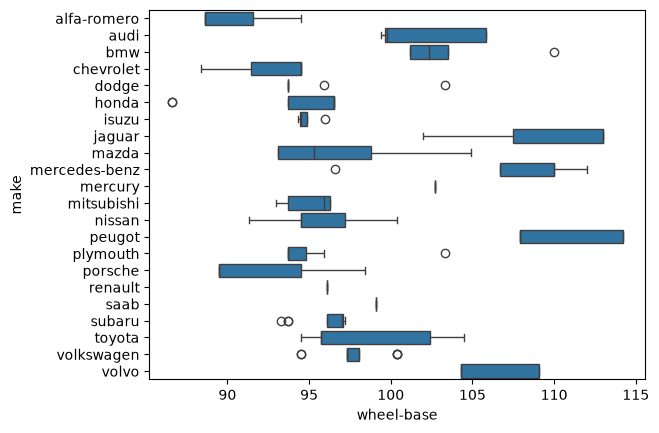

In [69]:
sns.boxplot(data=df,x='wheel-base',y='make')

In [70]:
df[(df['make']=='bmw') & (df['wheel-base']>105)]

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base
17,0,122.0,bmw,gas,std,four,sedan,rwd,front,110.0


In [71]:
df.drop(17,inplace=True)

<Axes: xlabel='wheel-base', ylabel='make'>

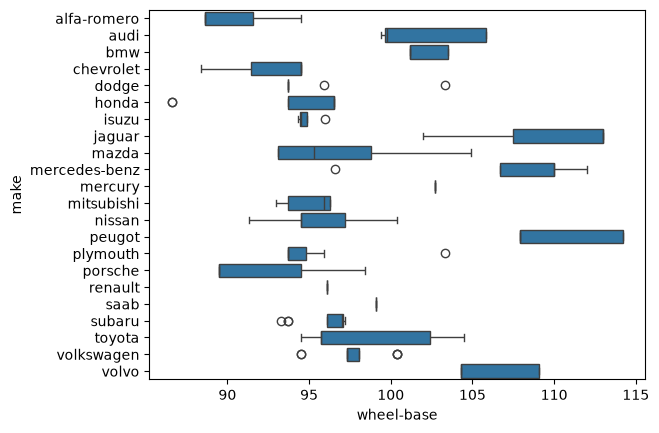

In [72]:
sns.boxplot(data=df,x='wheel-base',y='make')